# Week 2 Day 5 Lab - Self-Improvement

## An agent that improves our claim agent

On Day 1 we improved the claim agent by hand. We looked at its mistakes, gave it a payout tool and ran the experiment again. Today a new agent, the improver, runs that loop for us. It follows a recipe: read the results, propose a change, wait for a human to approve it, then run the evaluation again. The last step of the recipe is to improve the recipe.

To know whether a change helped, we need to measure more than accuracy. We add a judge that grades the agent's rationale against the handler's reason, and we measure cost and time as on Day 4.

## 4 parts:

PART 1: A judge with a reference answer

PART 2: Version 1 and its scores

PART 3: One round of improvement

PART 4: Improving the improver

<table style="margin: 0; text-align: left; width:100%">
    <tr>
        <td style="width: 150px; height: 150px; vertical-align: middle;">
            <img src="../../assets/stop.png" width="150" height="150" style="display: block;" />
        </td>
        <td>
            <h2 style="color:#EF476F;">Before you start</h2>
            <span style="color:#EF476F;">This lab calls GPT-6 Luna and Jev through OpenRouter and costs about 10 cents. If you'd rather not spend anything, there's a free version of this lab in <a href="week2day5free.ipynb">week2day5free.ipynb</a>.<br/><br/>
            You'll need the Langfuse keys you set up on Day 1.<br/><br/>
            Before today's product build, please follow Setting up for the product at the end of this lab.<br/><br/>
            The improver makes its own choices, so your rounds will go differently from mine. Please execute each cell in order and read what the improver proposes before you approve it.
            </span>
        </td>
    </tr>
</table>

### Local Postgres and local Supabase in this lab

*Only for running Postgres and Supabase on your own machine with Docker, as on Days 3 and 4.*

Parts 1 to 4 don't use a database. The improver keeps its pauses in memory with `InMemorySaver`, and UnderCover's data stays in Postgres 17 in the `undercover-postgres` container.

The setup for the product at the end needs Supabase Auth, for the handlers' sign-in. Postgres has no sign-in service, so we run Supabase's own stack on this machine with the Supabase CLI, in place of a Supabase project. It needs no Supabase account. The cells for it are under **Local Supabase** in **Setting up for the product**, and need Docker Desktop running.

In [1]:
import truststore

# Trust the certificates in the Windows certificate store, so HTTPS works behind a network that inspects traffic.
# This must run before anything opens a connection, or that connection keeps the old certificate check.
truststore.inject_into_ssl()

import difflib
import json
import operator
import os
from datetime import datetime
from pathlib import Path
from typing import Annotated, Literal, TypedDict

import pandas as pd
import requests
from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langfuse import get_client
from langfuse.langchain import CallbackHandler
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command, RetryPolicy, Send
from openrouter import OpenRouter
from week2day1_payout import Benefit, Line, Payout, work_out_payout

## Connect to OpenRouter and Langfuse

The keys come from the `.env` file in the `undercover` folder, with the Langfuse keys you added on Day 1.

In [2]:
load_dotenv(override=True)
openrouter_api_key = os.getenv("OPENROUTER_API_KEY")
OPENROUTER_BASE_URL = "https://openrouter.ai/api/v1"

if openrouter_api_key:
    print("OpenRouter API key found")
else:
    print("No OpenRouter API key found. Add OPENROUTER_API_KEY to the .env file")

OpenRouter API key found


In [3]:
langfuse = get_client()
langfuse_handler = CallbackHandler()

if langfuse.auth_check():
    print("Connected to Langfuse")
else:
    print("No Langfuse keys found. Add them to the .env file")

Connected to Langfuse


## Part 1: A judge with a reference answer

### The two sets of claims

We go back to the queue of 25 claims from Week 1, which is our evaluation set, and the 25 held-out claims that we've kept out of sight until now. The improver will learn from its mistakes on the evaluation set. The held-out set tells us whether a change works on claims it hasn't seen.

`get_sample_data` is the loader from Week 1 Day 2. If you'd like a quicker run, set `TINY = True` to keep 5 claims of each set.

In [4]:
DATA = Path("../../data")


def load(name):
    """Read one of the JSON seed files."""
    return json.loads((DATA / name).read_text(encoding="utf-8"))


def get_sample_data(tiny=False, held_out=False):
    """Return a list of claims, and the handlers' decisions on them keyed by claim id."""
    claims = load("evals/held_out_claims.json" if held_out else "claims.json")
    decisions = load("evals/held_out_decisions.json" if held_out else "evals/decisions.json")
    if tiny:
        chosen = {decision["claim_id"] for decision in decisions if decision["tiny"]}
        claims = [claim for claim in claims if claim["claim_id"] in chosen]
        decisions = [decision for decision in decisions if decision["tiny"]]
    labels = {decision["claim_id"]: decision for decision in decisions}
    return claims, labels

In [5]:
TINY = False

evaluation_claims, evaluation_labels = get_sample_data(tiny=TINY)
held_out_claims, held_out_labels = get_sample_data(tiny=TINY, held_out=True)

claims = {claim["claim_id"]: claim for claim in evaluation_claims + held_out_claims}
labels = evaluation_labels | held_out_labels
policies = {policy["policy_id"]: policy for policy in load("policies.json")}
policy_wording = (DATA / "policy_wording.md").read_text(encoding="utf-8")

SETS = {"evaluation": list(evaluation_labels), "held-out": list(held_out_labels)}
print(f"{len(SETS['evaluation'])} evaluation claims and {len(SETS['held-out'])} held-out claims")

25 evaluation claims and 25 held-out claims


### The handler's reason

Every decision in the two sets comes with the handler's reason and the part of the policy wording it relies on. Here's the first claim in the queue.

In [6]:
# Load the whole queue, in case TINY is True
queue_claims, queue_labels = get_sample_data()
handler = queue_labels["CLM-1001"]

print(f"Decision: {handler['decision']} ${handler['payout']:,.2f}")
print(f"Reason: {handler['reason']}")
print(f"Reference: {handler['reference']}")

Decision: approve $420.00
Reason: The carrier canceled the flight for a crew problem and the delay was 19 hours, well past the 6 hour waiting period on Premium. The hotel, meals and taxis are reasonable and all have receipts. The total is inside the $800 maximum.
Reference: Policy wording, section 3


### A reference-guided judge

On Day 1 we scored the decision and the payout with code. Whether the agent's rationale gives the right grounds is a judgement, so we ask a model. A judge is more reliable when it has a reference answer to compare against, and we have one: the handler's reason.

Our judge is Jev, the decision model we met on Week 1 Day 2, where it got 17 of 25 decisions right. Grading one rationale against another is a narrower question. Jev answers a `score` question by rating our grades in order, F, C, B and A. It gives each grade a probability and returns a score from 0 for F to 3 for A, weighted by those probabilities. We use the score as the grade, and the most likely grade as its letter. A is a high bar: the same grounds as the handler, better expressed.

Two `noul` questions in the same call say which part matched, since Jev doesn't write an explanation.

In [7]:
JEV = "typesafe/jev-1.13"

# Jev numbers the grades by their position in the list, so F is 0 and A is 3
RUBRIC = {
    "F": "different grounds from the handler's reason, or it contradicts the handler's reason",
    "C": "partly the same as the handler's reason: one of the handler's grounds or the section is missing, or it adds a ground the handler did not give",
    "B": "the same grounds and the same section of the policy wording as the handler's reason",
    "A": "the same grounds and section as the handler's reason, and clearly better expressed: clearer for the customer, with the section and the figures, shorter, and no jargon",
}
GRADES = list(RUBRIC)

JUDGE_QUESTIONS = {
    "grade": {
        "type": "score",
        "instructions": "An expert claims handler decided a travel insurance claim and gave `handler.reason`, resting on `handler.reference`. Grade how well `agent.rationale` explains the same decision.",
        "criteria": [f"{letter}: {text}" for letter, text in RUBRIC.items()],
    },
    "same_grounds": {"type": "noul", "instructions": "`agent.rationale` gives the same main grounds for the decision as `handler.reason`"},
    "same_section": {"type": "noul", "instructions": "`agent.rationale` refers to the same section of the policy wording as `handler.reference`"},
}

openrouter_decisions = OpenRouter(api_key=openrouter_api_key, timeout_ms=60_000)


def judge(rationale, decision, expected):
    """Ask Jev to grade a rationale against the handler's reason."""
    state = {
        "handler": {"decision": expected["decision"], "reason": expected["reason"], "reference": expected["reference"]},
        "agent": {"decision": decision, "rationale": rationale},
    }
    response = openrouter_decisions.alpha.decisions.create(model=JEV, state=state, questions=JUDGE_QUESTIONS)
    answers = response.answers
    probabilities = answers["grade"].probabilities
    most_likely = max(probabilities, key=probabilities.get)
    return {
        "grade": answers["grade"].score,
        "letter": GRADES[int(most_likely)],
        "same_grounds": answers["same_grounds"].noul,
        "same_section": answers["same_section"].noul,
        "judge_cost": response.usage.cost,
    }

### Checking the judge

Before we trust the judge, we try it on four rationales for CLM-1001 where we know the grade we'd give: the handler's own reason with its reference, the reason from a different claim, a vague one, and one that we've written to be clearer than the handler's.

In [8]:
other_claim = queue_labels["CLM-1003"]
tests = {
    "The handler's reason": f"{handler['reason']} ({handler['reference']})",
    "A different claim's reason": other_claim["reason"],
    "Vague": "The flight was canceled and the customer stayed in a hotel, so we approve the claim.",
    "Clearer than the handler": "Approved under section 3: the crew problem delayed your flight by 19 hours, past the 6 hour waiting period on Premium. We pay the $420 for your hotel, meals and taxis in full, since every item has a receipt and the total is under the $800 limit.",
}

rows = []
for name, rationale in tests.items():
    rows.append({"rationale": name, **judge(rationale, "approve", handler)})

pd.DataFrame(rows).round(2)

,rationale,grade,letter,same_grounds,same_section,judge_cost
0,The handler's reason,2.02,B,0.99,0.99,0.0
1,A different claim's reason,0.00,F,0.02,0.06,0.0
2,Vague,0.87,C,0.25,0.21,0.0
3,Clearer than the handler,2.88,A,0.98,0.98,0.0


The judge gives the grades we'd expect. Each call costs a few thousandths of a cent and takes a fraction of a second. If you run the cell again the grades barely move, but Jev isn't completely deterministic.

## Part 2: Version 1 and its scores

### The configuration

The improver can change three things about the claim agent: its instructions, its model and its reasoning level. We keep them together as a configuration, and every change becomes a new version. Version 1 is the agent from Day 4.

In [9]:
INSTRUCTIONS = """You are a claims handler at UnderCover Travel Insurance.
Decide the claim you are given, using the policy wording below and the customer's policy record.

Choose one decision:
- approve: the wording covers the claim and the required documents are attached. Work out the payout using section 10.
- decline: the wording does not cover the claim.
- refer: a colleague needs to look at it, because a required document is missing, or the story and the documents disagree, or the wording does not settle the question.

Use your tools to record your decision.
Use the payout tool to work out the payout on an approved claim, and record the payout it returns.
"""

versions = [{"version": 1, "instructions": INSTRUCTIONS, "model": "openai/gpt-6-luna", "reasoning_effort": "low"}]
current = 1

### The claim agent

The same tools and prompt as Day 4. `make_agent` builds the agent from a configuration.

In [10]:
recorded = {}


@tool(parse_docstring=True)
def record_decision(claim_id: str, rationale: str, decision: Literal["approve", "decline", "refer"], payout: float) -> str:
    """Record the decision on a claim in the claims system.

    Args:
        claim_id: The claim's id
        rationale: 2-3 sentences to explain the decision along with the relevant section of the policy
        decision: The decision on the claim
        payout: The amount to pay in US dollars, or 0 for a decline or a referral
    """
    if claim_id in recorded:
        return f"A decision is already recorded on {claim_id}, and decisions are final"
    if decision == "approve" and payout <= 0:
        return "An approval needs a payout above zero"
    recorded[claim_id] = {"decision": decision, "payout": payout, "rationale": rationale}
    return f"Recorded {decision} on {claim_id}"


@tool(parse_docstring=True)
def calculate_payout(policy_id: str, benefit: Benefit, lines: list[Line], paid_by_others: float = 0.0) -> Payout:
    """Work out the payout on an approved claim with UnderCover's payout rules.

    Args:
        policy_id: The customer's policy id
        benefit: The benefit the claim is paid under
        lines: The covered items and expenses, one for each line of the claim, with any excluded ones left out. A pair or a set counts as one item
        paid_by_others: Anything a carrier, hotel or other party has paid or refunded for the same loss

    Returns:
        The calculation, the payout and whether it needs sign-off
    """
    return work_out_payout(policies[policy_id], benefit, lines, paid_by_others)

In [11]:
def make_user_prompt(claim):
    """The customer's policy record and the claim, as JSON."""
    policy = policies[claim["policy_id"]]
    return f"""# Policy record

{json.dumps(policy, indent=2)}

# Claim

{json.dumps(claim, indent=2)}
"""


def make_agent(config):
    """Build the claim agent for one version of the configuration."""
    model = ChatOpenAI(model=config["model"], base_url=OPENROUTER_BASE_URL, api_key=openrouter_api_key,
                       reasoning_effort=config["reasoning_effort"], timeout=120, max_retries=5)
    return create_agent(model=model, tools=[record_decision, calculate_payout],
                        system_prompt=f"{config['instructions']}\n{policy_wording}\n")

### The dispatcher

Day 4's dispatcher, given the claims to work and the configuration to use. Each `Send` carries the claim's id and the configuration to a claim agent.

In [12]:
class Dispatch(TypedDict):
    """What the dispatcher keeps for one run."""

    config: dict
    claims: list[str]
    results: Annotated[list, operator.add]


def fan_out(state: Dispatch):
    """Send each claim to a claim agent, with the configuration to use."""
    return [Send("work_claim", {"claim_id": claim_id, "config": state["config"]}) for claim_id in state["claims"]]


def work_claim(task):
    """Run a claim agent on one claim and return its result."""
    claim_id = task["claim_id"]
    agent = make_agent(task["config"])
    started = datetime.now()
    result = agent.invoke({"messages": [{"role": "user", "content": make_user_prompt(claims[claim_id])}]})
    answer = recorded.get(claim_id, {"decision": "refer", "payout": 0.0, "rationale": "Nothing recorded"})
    cost = sum(message.response_metadata["token_usage"]["cost"] for message in result["messages"] if message.type == "ai")
    return {"results": [{"claim_id": claim_id, **answer, "cost": cost, "started": started, "finished": datetime.now()}]}


builder = StateGraph(Dispatch)
builder.add_node("work_claim", work_claim, retry_policy=RetryPolicy(max_attempts=3))
builder.add_conditional_edges(START, fan_out, ["work_claim"])
builder.add_edge("work_claim", END)
dispatcher = builder.compile()

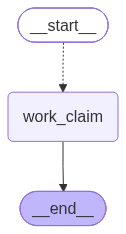

In [13]:
dispatcher

### Scoring a run

Day 1's code checks, with the judge's grade, the cost and the time for each claim. A run's scores are:

- `decision_accuracy`, `accuracy` and `cost_of_mistakes` from Day 1
- `grade`, the judge's average grade from 0 (F) to 3 (A)
- `cost_per_claim` and `seconds_per_claim` from Day 4

In [14]:
WRONGFUL_DECLINE = 1500
NEEDLESS_REFERRAL = 50


def is_right(answer, expected):
    """True when the decision matches the handler's and the payout is within a dollar."""
    return answer["decision"] == expected["decision"] and abs(answer["payout"] - expected["payout"]) <= 1


def mistake_cost(answer, expected):
    """What the agent's answer costs UnderCover, against the handler's decision."""
    if answer["decision"] == expected["decision"]:
        return abs(answer["payout"] - expected["payout"]) if answer["decision"] == "approve" else 0
    if answer["decision"] == "decline":
        return WRONGFUL_DECLINE
    if answer["decision"] == "approve":
        return answer["payout"]
    return NEEDLESS_REFERRAL

In [15]:
def score_table(results):
    """One row for each claim: the agent's answer beside the handler's, with the judge's grade, cost and time."""
    rows = []
    for answer in results:
        expected = labels[answer["claim_id"]]
        rows.append({
            "claim_id": answer["claim_id"],
            "handler": expected["decision"],
            "agent": answer["decision"],
            "handler_payout": expected["payout"],
            "agent_payout": answer["payout"],
            "right": is_right(answer, expected),
            "mistake_cost": mistake_cost(answer, expected),
            **judge(answer["rationale"], answer["decision"], expected),
            "llm_cost": answer["cost"],
            "seconds": (answer["finished"] - answer["started"]).total_seconds(),
            "rationale": answer["rationale"],
        })
    return pd.DataFrame(rows).sort_values("claim_id")


def run_scores(table):
    """The scores for a whole run: quality, cost and time."""
    return {
        "decision_accuracy": (table["agent"] == table["handler"]).mean(),
        "accuracy": table["right"].mean(),
        "cost_of_mistakes": table["mistake_cost"].sum(),
        "grade": table["grade"].mean(),
        "cost_per_claim": table["llm_cost"].mean(),
        "seconds_per_claim": table["seconds"].mean(),
    }

### Evaluating a version

`evaluate` runs one version on one set with 25 claim agents at once, scores it and keeps the result on the scoreboard. `spent` adds up what the runs cost, including the judge.

In [16]:
tables = {}
scoreboard = []
spent = 0.0


def evaluate(config, set_name):
    """Run one version of the configuration on one set, score it and add it to the scoreboard."""
    global spent
    recorded.clear()
    run_name = f"Version {config['version']} on the {set_name} set"
    result = dispatcher.invoke({"config": config, "claims": SETS[set_name]},
                               {"max_concurrency": 25, "callbacks": [langfuse_handler], "run_name": run_name})
    table = score_table(result["results"])
    scores = run_scores(table)
    spent += table["llm_cost"].sum() + table["judge_cost"].sum()
    tables[(config["version"], set_name)] = table
    scoreboard.append({"version": config["version"], "set": set_name, **scores})
    print(f"{run_name}: accuracy {scores['accuracy']:.2f}, grade {scores['grade']:.2f}, "
          f"${scores['cost_per_claim']:.5f} and {scores['seconds_per_claim']:.1f} seconds a claim")
    return scores

### Version 1

First the evaluation set, then the held-out set. Each takes about as long as its slowest claim.

In [17]:
evaluate(versions[0], "evaluation")
evaluate(versions[0], "held-out")

pd.DataFrame(scoreboard).round(4)

Version 1 on the evaluation set: accuracy 0.68, grade 1.16, $0.00036 and 6.6 seconds a claim
Version 1 on the held-out set: accuracy 0.72, grade 1.24, $0.00033 and 5.6 seconds a claim


,version,set,decision_accuracy,accuracy,cost_of_mistakes,grade,cost_per_claim,seconds_per_claim
0,1,evaluation,0.72,0.68,2528.0,1.1612,0.0004,6.6462
1,1,held-out,0.72,0.72,3625.0,1.2428,0.0003,5.6099


Here are the evaluation claims that version 1 got wrong. The improver will read these, with the right decisions it explained least well.

In [18]:
table = tables[(1, "evaluation")]
table[~table["right"]][["claim_id", "handler", "agent", "handler_payout", "agent_payout", "letter", "grade", "rationale"]].round(2)

,claim_id,handler,agent,handler_payout,agent_payout,letter,grade,rationale
12,CLM-1013,decline,approve,0.0,123.0,F,0.61,Approve under section 3: the Economy plan requ...
17,CLM-1018,refer,approve,0.0,330.0,F,0.12,The theft occurred during the covered trip and...
18,CLM-1019,refer,approve,0.0,98.0,F,0.04,Approve under section 3: the carrier confirms ...
19,CLM-1020,approve,decline,240.0,0.0,F,0.04,"Section 5 covers loss, theft, or accidental da..."
20,CLM-1021,approve,approve,825.0,730.0,C,0.66,Approve the stolen listed belongings: the poli...
22,CLM-1023,refer,approve,0.0,61.0,F,0.10,Approve under section 3: the First plan’s trip...
23,CLM-1024,refer,approve,0.0,250.0,F,0.21,The phone was stolen during the covered trip a...
24,CLM-1025,refer,approve,0.0,71.0,F,0.08,The documented delay was 14 hours and 15 minut...


### How much do the scores move?

The same version can score differently from one run to the next. Before we judge a change, we need to know how much the scores move with no change at all, so we run version 1 on the held-out set again. Every new version will get two runs on the held-out set too.

In [19]:
evaluate(versions[0], "held-out")

pd.DataFrame(scoreboard).round(4)

Version 1 on the held-out set: accuracy 0.68, grade 1.35, $0.00024 and 5.9 seconds a claim


,version,set,decision_accuracy,accuracy,cost_of_mistakes,grade,cost_per_claim,seconds_per_claim
0,1,evaluation,0.72,0.68,2528.0,1.1612,0.0004,6.6462
1,1,held-out,0.72,0.72,3625.0,1.2428,0.0003,5.6099
2,1,held-out,0.72,0.68,4260.0,1.3496,0.0002,5.8619


Compare the two runs on the held-out set. With only 25 claims, accuracy can move by a few claims with no change to the agent, and the grade and the time move too. A change has to move a score by more than that before we believe it, so we compare the average of a new version's two runs with the average of the current version's.

## Part 3: One round of improvement

### What the improver is aiming for

The improver is looking for a better version: more accurate, closer to the handlers' reasoning, cheaper or faster, and never below UnderCover's business objectives. These settings belong to the business, so they live in code where the improver can't change them:

- **The objectives:** a floor on accuracy and on the judge's grade, measured on the held-out set
- **The noise:** how far a score has to improve before we count it
- **The tolerance:** how far a score can get worse in a version that improves another
- **The budget:** what the improver can spend on evaluations in this lab
- **The models allowed:** the models and reasoning levels the claim agent may use

A new version is kept when it meets the objectives, at least one score improves by more than the noise, and none gets worse by more than the tolerance. Otherwise we roll back to the version before.

In [20]:
OBJECTIVES = {"accuracy": 0.6, "grade": 1.0}
NOISE = {"accuracy": 0.1, "grade": 0.15, "cost_per_claim": 0.15, "seconds_per_claim": 0.15}
TOLERANCE = {"accuracy": 0.1, "grade": 0.15, "cost_per_claim": 1.0, "seconds_per_claim": 0.25}
BUDGET = 0.50

ALLOWED_MODELS = {
    "openai/gpt-6-luna": {"reasoning_efforts": ["none", "low", "medium"], "price per million tokens": "$0.10 in, $0.50 out"},
    "google/gemini-3.5-flash-lite": {"reasoning_efforts": ["minimal", "low"], "price per million tokens": "$0.30 in, $2.50 out"},
    "deepseek/deepseek-v4.1-flash": {"reasoning_efforts": ["low"], "price per million tokens": "$0.30 in, $1.20 out"},
}

Cost and time are compared as a fraction of the old value, so 0.15 means 15% and 1.0 means double. Accuracy and the grade are compared as a difference.

A new version can cost up to double, since a claim costs a few hundredths of a cent and a new prompt costs more at first. OpenAI's prompt cache already holds version 1's prompt from earlier runs, and it takes a few runs to hold a new one.

These numbers are rough. With 25 claims a run, a lucky run can still get through.

In [21]:
def compare(new, old):
    """Which scores got better by more than the noise, and which got worse by more than the tolerance."""
    better, worse = [], []
    for name in ["accuracy", "grade"]:
        if new[name] > old[name] + NOISE[name]:
            better.append(name)
        if new[name] < old[name] - TOLERANCE[name]:
            worse.append(name)
    for name in ["cost_per_claim", "seconds_per_claim"]:
        if new[name] < old[name] * (1 - NOISE[name]):
            better.append(name)
        if new[name] > old[name] * (1 + TOLERANCE[name]):
            worse.append(name)
    return better, worse


def keep_or_roll_back(new, old):
    """Decide whether to keep a new version from its held-out scores and the current version's average."""
    missed = [name for name, floor in OBJECTIVES.items() if new[name] < floor]
    better, worse = compare(new, old)
    if missed:
        return False, f"it missed the objectives on {', '.join(missed)}"
    if worse:
        return False, f"{', '.join(worse)} got worse"
    if not better:
        return False, "no score improved by more than the noise"
    return True, f"{', '.join(better)} improved"

### The improver's tools

The improver reads results and proposes changes, and code does the rest. On the evaluation set it sees the claims the agent got wrong and the right decisions it explained least well, with the handlers' reasons. From the held-out set it sees only the scores.

`latest` finds the most recent scores for a version on a set, and `average` averages all its runs on a set. `beside_handler` puts the agent's answers beside the handlers' reasons.

In [22]:
rounds = []


def latest(version, set_name):
    """The most recent scores for a version on a set."""
    return [row for row in scoreboard if row["version"] == version and row["set"] == set_name][-1]


def average(version, set_name):
    """The average of a version's scores over all its runs on a set."""
    runs = pd.DataFrame([row for row in scoreboard if row["version"] == version and row["set"] == set_name])
    return runs.drop(columns=["version", "set"]).mean().to_dict()


def beside_handler(table):
    """Each claim in a table with the agent's answer beside the handler's and the judge's grade."""
    rows = []
    for row in table.to_dict("records"):
        expected = labels[row["claim_id"]]
        rows.append({
            "claim_id": row["claim_id"],
            "summary": claims[row["claim_id"]]["summary"],
            "agent": {"decision": row["agent"], "payout": row["agent_payout"], "rationale": row["rationale"]},
            "handler": {"decision": expected["decision"], "payout": expected["payout"], "reason": expected["reason"], "reference": expected["reference"]},
            "judge": {"grade": round(row["grade"], 2), "letter": row["letter"]},
        })
    return rows


def mistakes(version):
    """The evaluation claims a version got wrong, and the five right ones with the lowest grades."""
    table = tables[(version, "evaluation")]
    weakest = table[table["right"]].sort_values("grade").head(5)
    return {"wrong": beside_handler(table[~table["right"]]), "explained_least_well": beside_handler(weakest)}

In [23]:
@tool
def read_results() -> str:
    """Read the current version of the claim agent's configuration, its scores, its mistakes and weakest explanations on the evaluation set, the earlier rounds, the objectives, the budget and the models allowed."""
    config = versions[current - 1]
    report = {
        "current_version": config,
        "scores": {set_name: average(current, set_name) for set_name in SETS},
        "evaluation_set": mistakes(current),
        "earlier_rounds": rounds,
        "objectives_on_the_held_out_set": OBJECTIVES,
        "noise": NOISE,
        "tolerance": TOLERANCE,
        "rule": "A new version is kept when it meets the objectives, at least one score improves by more than the noise and none gets worse by more than the tolerance",
        "budget_left": round(BUDGET - spent, 4),
        "models_allowed": ALLOWED_MODELS,
    }
    return json.dumps(report, indent=2, default=str)

In [24]:
@tool(parse_docstring=True)
def propose_change(instructions: str, model: str, reasoning_effort: str, reason: str) -> str:
    """Propose a new version of the claim agent's configuration. A human reviews it before it's saved.

    Args:
        instructions: The claim agent's complete instructions
        model: One of the models allowed
        reasoning_effort: A reasoning level allowed for that model
        reason: Why this change should improve the scores
    """
    if reasoning_effort not in ALLOWED_MODELS.get(model, {}).get("reasoning_efforts", []):
        return f"{model} at {reasoning_effort} isn't allowed. Choose from the models allowed."
    version = len(versions) + 1
    versions.append({"version": version, "instructions": instructions, "model": model, "reasoning_effort": reasoning_effort, "reason": reason})
    return f"Saved as version {version}. Run the evaluation next."

In [25]:
@tool
def run_evaluation() -> str:
    """Run the newest version once on the evaluation set and twice on the held-out set, then keep it or roll it back."""
    global current
    config = versions[-1]
    if config["version"] == current or any(r["version"] == config["version"] for r in rounds):
        return "There's no new version to evaluate. Propose a change first."
    estimate = 3 * len(SETS["held-out"]) * max(row["cost_per_claim"] for row in scoreboard)
    if spent + estimate > BUDGET:
        return f"Refused: the evaluation could cost about ${estimate:.2f} and ${BUDGET - spent:.2f} of the budget is left"
    before = average(current, "held-out")
    evaluate(config, "evaluation")
    evaluate(config, "held-out")
    evaluate(config, "held-out")
    after = average(config["version"], "held-out")
    keep, why = keep_or_roll_back(after, before)
    rounds.append({"round": len(rounds) + 1, "recipe_version": len(recipes), "version": config["version"],
                   "model": config["model"], "reasoning_effort": config["reasoning_effort"], "reason": config["reason"],
                   "kept": keep, "why": why, "held_out_before": before, "held_out_after": after})
    if keep:
        current = config["version"]
    verdict = "Kept" if keep else "Rolled back"
    scores = {"held_out_before": before, "held_out_after": after, "evaluation_after": latest(config["version"], "evaluation")}
    return f"{verdict} version {config['version']}: {why}. Version {current} is now the current version.\n{json.dumps(scores, indent=2)}"

In [26]:
recipes = []


@tool(parse_docstring=True)
def propose_recipe(recipe: str, reason: str) -> str:
    """Propose a new version of your recipe for improving the claim agent. A human reviews it before it's saved.

    Args:
        recipe: The complete new recipe
        reason: What this round showed, and why the new recipe should lead to better changes
    """
    recipes.append(recipe)
    return f"Saved as recipe version {len(recipes)}."

### The recipe

The improver's instructions are its recipe. We start it with a simple one that fixes mistakes one at a time. The last step asks the improver to improve the recipe itself.

In [27]:
RECIPE = """1. Call read_results to see how the current version is doing and which evaluation claims it got wrong or explained poorly.
2. For each of those claims, add a rule to the instructions that would make the agent get that claim right.
3. Call propose_change with the new instructions, keeping the same model and reasoning level.
4. Call run_evaluation to test the new version on both sets.
5. Improve this recipe, so that the next round makes a better change. Look at what happened in this round and in earlier rounds, then call propose_recipe with the new recipe. Keep this as the last step of the new recipe.
"""

recipes.append(RECIPE)

### The improver

The improver is a LangChain agent with the recipe in its instructions. On Day 3 we wrote `interrupt()` by hand to wait for a handler. LangChain's `HumanInTheLoopMiddleware` does the same for chosen tools: when the improver calls `propose_change` or `propose_recipe`, the run pauses until a human approves or rejects the call. The pause needs a checkpointer, as on Day 3.

The improver uses Luna at `medium`, since writing a good change takes more thought than deciding a claim.

In [28]:
improver_model = ChatOpenAI(model="openai/gpt-6-luna", base_url=OPENROUTER_BASE_URL, api_key=openrouter_api_key,
                            reasoning_effort="medium", timeout=300, max_retries=5)

approval = HumanInTheLoopMiddleware(interrupt_on={
    "propose_change": {"allowed_decisions": ["approve", "reject"]},
    "propose_recipe": {"allowed_decisions": ["approve", "reject"]},
})


def make_improver(recipe):
    """Build the improver with a recipe as its instructions."""
    system_prompt = f"""You improve the configuration of UnderCover's claim agent, an AI agent that decides travel insurance claims.
The claim agent sees its instructions, the policy wording, the customer's policy record and the claim. It doesn't see the claims manual or the customer's history.
Follow your recipe one step at a time.

# Your recipe

{recipe}
"""
    return create_agent(model=improver_model, tools=[read_results, propose_change, run_evaluation, propose_recipe],
                        system_prompt=system_prompt, middleware=[approval], checkpointer=InMemorySaver())

`show_proposal` prints what the improver is asking to do: for a change, the model, the reasoning level and the lines of the instructions that change; for a recipe, the lines of the recipe that change.

In [29]:
def show_changed_lines(old, new):
    """Print the lines that differ between two texts."""
    for line in difflib.unified_diff(old.splitlines(), new.splitlines(), lineterm="", n=0):
        if not line.startswith(("---", "+++", "@@")):
            print(line)


def show_proposal(result):
    """Show the change the improver is waiting for us to approve."""
    if "__interrupt__" not in result:
        print("The improver finished without a proposal. Its last message:")
        print(result["messages"][-1].content)
        return
    request = result["__interrupt__"][0].value["action_requests"][0]
    args = request["args"]
    if request["name"] == "propose_change":
        old = versions[current - 1]
        print(f"Model: {old['model']} at {old['reasoning_effort']}, proposed {args['model']} at {args['reasoning_effort']}\n")
        show_changed_lines(old["instructions"], args["instructions"])
    else:
        print(f"Recipe version {len(recipes)}, proposed version {len(recipes) + 1}\n")
        show_changed_lines(recipes[-1], args["recipe"])
    print(f"\nReason: {args['reason']}")

### Round 1

The improver reads the results and proposes a change. The run pauses before the change is saved. The metadata puts all the improver's traces in one Langfuse session.

In [30]:
session = f"Improvement {datetime.now():%Y-%m-%d %H:%M}"
improver = make_improver(recipes[-1])
round_1 = {"configurable": {"thread_id": "round-1"}, "callbacks": [langfuse_handler], "run_name": "Improver round 1",
           "metadata": {"langfuse_session_id": session}}

result = improver.invoke({"messages": [{"role": "user", "content": "Please carry out one round of your recipe."}]}, round_1)
show_proposal(result)

Model: openai/gpt-6-luna at low, proposed openai/gpt-6-luna at low

+Apply these checks carefully:
+- For Trip Delay, compare the documented elapsed delay with the exact waiting period for the customer's plan. If it is below the threshold, decline; do not approve or calculate a payout. Also verify the carrier's evidence confirms both the delay and a covered cause where the wording requires a covered cause. If the carrier confirms the timing but not the cause, and the cause is only stated by the customer, refer for carrier confirmation rather than approving.
+- For baggage/personal belongings, distinguish the kind of event. An item taken directly from the insured by a wild animal is accidental loss, not theft; do not require a police report for that event, and do not treat a wild animal as vermin or a pet. Use other acceptable evidence (such as a guide's letter) to support what happened. For ordinary theft, apply the policy's police-report requirement.
+- Check evidence of value as well

If you're happy with the change, run the next cell to approve it. The improver then runs the evaluation, once on the evaluation set and twice on the held-out set, which takes a couple of minutes. Our code keeps the new version or rolls it back.

To turn the change down instead, resume with `{"type": "reject", "message": "your reason"}` and the improver will see your reason.

In [31]:
APPROVE = Command(resume={"decisions": [{"type": "approve"}]})

result = improver.invoke(APPROVE, round_1)
pd.DataFrame(scoreboard).round(4)

Version 2 on the evaluation set: accuracy 0.80, grade 1.53, $0.00041 and 5.7 seconds a claim
Version 2 on the held-out set: accuracy 0.80, grade 1.52, $0.00036 and 5.7 seconds a claim
Version 2 on the held-out set: accuracy 0.72, grade 1.51, $0.00026 and 5.0 seconds a claim


,version,set,decision_accuracy,accuracy,cost_of_mistakes,grade,cost_per_claim,seconds_per_claim
0,1,evaluation,0.72,0.68,2528.0,1.1612,0.0004,6.6462
1,1,held-out,0.72,0.72,3625.0,1.2428,0.0003,5.6099
2,1,held-out,0.72,0.68,4260.0,1.3496,0.0002,5.8619
3,2,evaluation,0.80,0.80,571.0,1.5332,0.0004,5.7389
4,2,held-out,0.80,0.80,2255.0,1.5192,0.0004,5.7294
5,2,held-out,0.76,0.72,5245.0,1.5140,0.0003,5.0428


In [32]:
def show_rounds():
    """One row for each round: the version it tried, the held-out scores before and after, and the verdict."""
    rows = []
    for r in rounds:
        rows.append({
            "round": r["round"], "recipe": r["recipe_version"], "version": r["version"],
            "model": r["model"], "reasoning": r["reasoning_effort"],
            "accuracy_before": r["held_out_before"]["accuracy"], "accuracy_after": r["held_out_after"]["accuracy"],
            "grade_before": r["held_out_before"]["grade"], "grade_after": r["held_out_after"]["grade"],
            "kept": r["kept"], "why": r["why"],
        })
    return pd.DataFrame(rows).round(2)


show_rounds()

,round,recipe,version,model,reasoning,accuracy_before,accuracy_after,grade_before,grade_after,kept,why
0,1,1,2,openai/gpt-6-luna,low,0.7,0.76,1.3,1.52,True,grade improved


<table style="margin: 0; text-align: left; width:100%">
    <tr>
        <td style="width: 150px; height: 150px; vertical-align: middle;">
            <img src="../../assets/info.png" width="150" height="150" style="display: block;" />
        </td>
        <td>
            <h2 style="color:#118AB2;">Gains on the held-out set</h2>
            <span style="color:#118AB2;">It's easy to improve an agent on the claims you're looking at. A rule written for one claim fixes that claim, and the evaluation set's score goes up whether or not the rule helps anywhere else. That's overfitting.<br/><br/>
            So the improver never reads the held-out claims, and our code decides from the held-out scores alone. If the improver could read them, it could write rules for them too, and the held-out scores would stop telling us anything.
            </span>
        </td>
    </tr>
</table>

## Part 4: Improving the improver

### The recipe's last step

After the evaluation, the improver has reached the last step of its recipe. It has seen what its change did on both sets, and now it proposes a new recipe. Here's what it wants to change.

In [33]:
show_proposal(result)

Recipe version 1, proposed version 2

-1. Call read_results to see how the current version is doing and which evaluation claims it got wrong or explained poorly.
-2. For each of those claims, add a rule to the instructions that would make the agent get that claim right.
-3. Call propose_change with the new instructions, keeping the same model and reasoning level.
-4. Call run_evaluation to test the new version on both sets.
-5. Improve this recipe, so that the next round makes a better change. Look at what happened in this round and in earlier rounds, then call propose_recipe with the new recipe. Keep this as the last step of the new recipe.
+1. Call read_results. Identify the evaluation claims with wrong decisions/payouts and the weakest explanations; note baseline and held-out metrics, the current instructions/model/reasoning level, available budget, and any earlier-round patterns.
+2. For each error, separate (a) the actual decision/payout rule implicated from (b) a rationale-only w

In [34]:
result = improver.invoke(APPROVE, round_1)
print(result["messages"][-1].content)

Completed one round. Version 2 was kept after evaluation: evaluation accuracy rose from 0.68 to 0.80, while held-out accuracy rose from 0.70 to 0.76 and grade from 1.2962 to 1.5166. Held-out mistake cost also fell from 3942.5 to 3750.0.

I updated the recipe to better distinguish decision errors from explanation weaknesses, map errors to reusable rules, and avoid relying on information the agent cannot see.


### Round 2

A new improver starts from the new recipe. Each round can improve the recipe as well as the claim agent, so the improver itself can get better from one round to the next. This is recursive self-improvement on a small scale.

In [35]:
improver = make_improver(recipes[-1])
round_2 = {"configurable": {"thread_id": "round-2"}, "callbacks": [langfuse_handler], "run_name": "Improver round 2",
           "metadata": {"langfuse_session_id": session}}

result = improver.invoke({"messages": [{"role": "user", "content": "Please carry out one round of your recipe."}]}, round_2)
show_proposal(result)

Model: openai/gpt-6-luna at low, proposed openai/gpt-6-luna at low

-- Check evidence of value as well as evidence that an event happened. Refer for proof of value for an individual claimed item valued above $100 when no receipt, card statement, or other value evidence is supplied. An item valued at $100 or less may be accepted at the customer's stated value without a receipt. Do not omit an otherwise eligible low-value item merely because it lacks a receipt.
+- Check evidence of value as well as evidence that an event happened. Refer for proof of value for an individual claimed item valued above $100 when no receipt, card statement, or other value evidence is supplied. An item valued at $100 or less may be accepted at the customer's stated value without a receipt. Do not omit an otherwise eligible low-value item merely because it lacks a receipt. When the customer gives a quantity and a single aggregate value for a group of comparable items (for example, several identical garments), u

In [36]:
result = improver.invoke(APPROVE, round_2)
show_proposal(result)

Version 3 on the evaluation set: accuracy 0.80, grade 1.54, $0.00039 and 5.5 seconds a claim
Version 3 on the held-out set: accuracy 0.76, grade 1.44, $0.00037 and 5.6 seconds a claim
Version 3 on the held-out set: accuracy 0.68, grade 1.40, $0.00028 and 5.5 seconds a claim
Recipe version 2, proposed version 3

-1. Call read_results. Identify the evaluation claims with wrong decisions/payouts and the weakest explanations; note baseline and held-out metrics, the current instructions/model/reasoning level, available budget, and any earlier-round patterns.
-2. For each error, separate (a) the actual decision/payout rule implicated from (b) a rationale-only weakness. Add only broadly reusable rules supported by the supplied policy wording, record, or error evidence. Do not encode inaccessible manual/history details as if the agent can see them; instead state that the agent must base decisions only on materials it receives and refer only when those materials leave a policy-required issue un

In [37]:
result = improver.invoke(APPROVE, round_2)
print(result["messages"][-1].content)

Completed one round. The attempted version 3 change was **rolled back**, so version 2 remains current.

- **Held-out:** accuracy fell from 0.76 to 0.72, grade from 1.5166 to 1.4196, and cost of mistakes rose from $3,750 to $6,493.
- **Evaluation:** accuracy remained 0.80; grade rose from 1.5332 to 1.5352, below the noise threshold.

The change did not meet the keep criterion. I saved recipe version 3 to guide the next round toward isolating the cause of the regression, preserving effective version-2 rules, and avoiding unsupported or overbroad instructions.


### The scoreboard

Every run of every version, then the rounds with the recipe version that produced each change.

In [38]:
pd.DataFrame(scoreboard).round(4)

,version,set,decision_accuracy,accuracy,cost_of_mistakes,grade,cost_per_claim,seconds_per_claim
0,1,evaluation,0.72,0.68,2528.0,1.1612,0.0004,6.6462
1,1,held-out,0.72,0.72,3625.0,1.2428,0.0003,5.6099
2,1,held-out,0.72,0.68,4260.0,1.3496,0.0002,5.8619
3,2,evaluation,0.80,0.80,571.0,1.5332,0.0004,5.7389
4,2,held-out,0.80,0.80,2255.0,1.5192,0.0004,5.7294
5,2,held-out,0.76,0.72,5245.0,1.5140,0.0003,5.0428
6,3,evaluation,0.80,0.80,4600.0,1.5352,0.0004,5.4833
7,3,held-out,0.76,0.76,6420.0,1.4364,0.0004,5.6268
8,3,held-out,0.72,0.68,6566.0,1.4028,0.0003,5.4905


In [39]:
show_rounds()

,round,recipe,version,model,reasoning,accuracy_before,accuracy_after,grade_before,grade_after,kept,why
0,1,1,2,openai/gpt-6-luna,low,0.70,0.76,1.30,1.52,True,grade improved
1,2,2,3,openai/gpt-6-luna,low,0.76,0.72,1.52,1.42,False,no score improved by more than the noise


In [40]:
print(f"Current version: {current}")
print(f"Spent on evaluations: ${spent:.4f} of ${BUDGET:.2f}")

Current version: 2
Spent on evaluations: $0.0819 of $0.50


In Langfuse, open **Sessions** and the session called `Improvement` with today's date. It has a trace for each stretch of the improver's work between your approvals. The evaluations are inside the improver's traces, with every claim agent.

<table style="margin: 0; text-align: left; width:100%">
    <tr>
        <td style="width: 150px; height: 150px; vertical-align: middle;">
            <img src="../../assets/business.png" width="150" height="150" style="display: block;" />
        </td>
        <td>
            <h2 style="color:#118AB2;">Commercial implications</h2>
            <span style="color:#118AB2;">An improver can keep a deployed agent getting better after the project team has moved on. The business sets the objectives and a person approves each change. The same loop works for any agent with a labelled set of past decisions, such as support replies, invoice checks or contract reviews.<br/><br/>
            Consider which of your business's agents has enough past decisions to make an evaluation set and a held-out set.
            </span>
        </td>
    </tr>
</table>

<table style="margin: 0; text-align: left; width:100%">
    <tr>
        <td style="width: 150px; height: 150px; vertical-align: middle;">
            <img src="../../assets/exercise.png" width="150" height="150" style="display: block;" />
        </td>
        <td>
            <h2 style="color:#EF476F;">Your assignment</h2>
            <span style="color:#EF476F;">Challenge: give the improver another lever. Add the concise policy wording in <code>data/policy_wording_short.md</code> as a choice in the configuration, and see whether the improver finds a cheaper prompt that still meets the objectives.<br/><br/>
            I'd love it if you would consider making a PR with your version of the lab in the <code>community_contributions</code> folder. There are instructions on making a PR at <a href="https://edwarddonner.com/pr">edwarddonner.com/pr</a>.
            </span>
        </td>
    </tr>
</table>

## Setting up for the product

In today's product build, the handlers sign in to the dashboard, and the improver works inside the product within a spending limit. Both need some setup first: the handlers as users in Supabase, three new lines in your `.env` file and a credit limit on your OpenRouter key. It takes about ten minutes.

If you've come straight here, run the lab's first three code cells first.

### Local Supabase: an option in place of a Supabase project

*Only for Supabase on your own machine.* The next cell starts Supabase's local stack from `supabase/config.toml` in the `undercover` folder. It runs the Supabase CLI with `npx`, so there's nothing to install. The first start downloads the stack's images and takes a few minutes. After that it starts in under a minute.

- The stack brings Auth, a dashboard called Studio at http://127.0.0.1:54323, and a Postgres of its own on port 54322. That Postgres holds only the sign-in users. UnderCover's data stays in `undercover-postgres` on port 5432.
- `supabase/config.toml` already turns off sign-ups, so you can skip step 4 below.
- **If `.env` has no `VITE_SUPABASE_URL` yet**, the cell adds `VITE_SUPABASE_URL` and `VITE_SUPABASE_PUBLISHABLE_KEY` for the local stack, and a random `HANDLER_PASSWORD` if there's none.
- **If `VITE_SUPABASE_URL` points to a Supabase project**, it leaves `.env` alone.

The address uses `127.0.0.1`, not `localhost`, for the same reason as Postgres.

In [41]:
import secrets
import shutil
import string
import subprocess

ROOT = Path("../..")
ENV_FILE = ROOT / ".env"
SUPABASE_CLI = [shutil.which("npx") or "npx", "--yes", "supabase@2.122.0"]


def supabase(*args):
    """Run a Supabase CLI command on the project in the undercover folder and return what it printed."""
    result = subprocess.run([*SUPABASE_CLI, *args, "--workdir", str(ROOT)], capture_output=True, text=True)
    if result.returncode != 0:
        raise RuntimeError(result.stderr.strip() or f"supabase {args[0]} failed")
    return result.stdout


try:
    local_supabase = json.loads(supabase("status", "-o", "json"))
    print("Local Supabase is running")
except RuntimeError:
    print("Starting local Supabase. The first start downloads its images and takes a few minutes")
    supabase("start")
    local_supabase = json.loads(supabase("status", "-o", "json"))
    print("Started local Supabase")

load_dotenv(override=True)
supabase_url = os.getenv("VITE_SUPABASE_URL")
if not supabase_url:
    lines = [f"VITE_SUPABASE_URL={local_supabase['API_URL']}", f"VITE_SUPABASE_PUBLISHABLE_KEY={local_supabase['PUBLISHABLE_KEY']}"]
    if not os.getenv("HANDLER_PASSWORD"):
        lines.append("HANDLER_PASSWORD=" + "".join(secrets.choice(string.ascii_letters + string.digits) for _ in range(16)))
    with ENV_FILE.open("a", encoding="utf-8") as env:
        env.write("\n# Local Supabase Auth (npx supabase start)\n" + "\n".join(lines) + "\n")
    print("Added the local Supabase settings to .env")
elif supabase_url == local_supabase["API_URL"]:
    print("The local Supabase settings are already in .env")
else:
    print("VITE_SUPABASE_URL in .env points to a Supabase project, so .env is unchanged. Remove the Supabase lines from .env to use local Supabase")

print(f"Studio: {local_supabase['STUDIO_URL']}")

Local Supabase is running
The local Supabase settings are already in .env
Studio: http://127.0.0.1:54323


### The handlers in Supabase Auth

Our three claims handlers are in `data/handlers.json`. In the product, a handler signs in to the dashboard with their email address and a password, and the backend looks them up by email to see whether they can sign off a payout over the limit. The addresses are made up, so we add the users by hand and Supabase never emails them.

In [42]:
handlers = json.loads(Path("../../data/handlers.json").read_text())
for handler in handlers:
    print(f"{handler['email']}  ({handler['name']}, {handler['role']})")

dana.whitfield@undercover.example  (Dana Whitfield, Senior Claims Handler)
marcus.oyelaran@undercover.example  (Marcus Oyelaran, Claims Handler)
priya.raman@undercover.example  (Priya Raman, Claims Handler)


In your Supabase project:

1. Open **Authentication**, then **Users**.
2. Press **Add user** and choose **Create new user**. Enter the first handler's email address and a password, keep **Auto Confirm User** ticked, and press **Create user**.
3. Do the same for the other two handlers, with the same password.
4. Still in **Authentication**, open **Sign In / Providers**, turn off **Allow new users to sign up** and save. Then nobody else can make an account when the dashboard goes on the internet in Week 3.

### Local Supabase: adding the handlers

*Only for local Supabase.* Studio at http://127.0.0.1:54323 has the same **Authentication** pages, so the steps above work there too. Or run the next cell, which adds the three handlers with the password in `.env`. It uses the local stack's secret key, which works only on this machine's stack. Skip step 4: sign-ups are already off.

In [43]:
load_dotenv(override=True)
admin = {"apikey": local_supabase["SECRET_KEY"]}

for handler in handlers:
    user = {"email": handler["email"], "password": os.getenv("HANDLER_PASSWORD"), "email_confirm": True}
    response = requests.post(f"{local_supabase['API_URL']}/auth/v1/admin/users", headers=admin, json=user)
    if response.ok:
        print(f"Added {handler['name']}")
    elif response.json().get("error_code") == "email_exists":
        print(f"{handler['name']} is already a user")
    else:
        print(f"Couldn't add {handler['name']}: {response.json().get('msg')}")

Dana Whitfield is already a user
Marcus Oyelaran is already a user
Priya Raman is already a user


### Three lines in your .env file

Press **Connect** at the top of your Supabase project's page. It shows the project URL and the publishable key, which starts `sb_publishable_`. Add both to the `.env` file in the `undercover` folder, with the handlers' password:

```
VITE_SUPABASE_URL=https://your-project-ref.supabase.co
VITE_SUPABASE_PUBLISHABLE_KEY=sb_publishable_...
HANDLER_PASSWORD=the password you gave the handlers
```

The dashboard sends the URL and the publishable key to the browser, and they're meant to be public. Vite, the dashboard's build tool, only sends variables whose names start with `VITE_`, so the password stays out of the browser. Claude Code uses it to sign in when it checks the dashboard.

There's no secret key from Supabase here. Supabase signs each sign-in with a private key it keeps to itself and publishes the matching public key, so our backend can check a sign-in without any secret. Your `DATABASE_URL` holds the database password and stays private, as before.

### Local Supabase: the three lines

*Only for local Supabase.* The start cell above already added these lines to `.env`, with the local address `http://127.0.0.1:54321` and the local publishable key. The next two cells work the same on the local stack. The local stack also publishes its public key at `/auth/v1/.well-known/jwks.json`, so the check finds it.

In [44]:
load_dotenv(override=True)
supabase_url = os.getenv("VITE_SUPABASE_URL")
publishable_key = os.getenv("VITE_SUPABASE_PUBLISHABLE_KEY")
handler_password = os.getenv("HANDLER_PASSWORD")

if supabase_url and publishable_key and handler_password:
    print("Supabase settings found")
else:
    print("Add VITE_SUPABASE_URL, VITE_SUPABASE_PUBLISHABLE_KEY and HANDLER_PASSWORD to the .env file")

Supabase settings found


### Checking the sign-ins

This cell asks Supabase whether sign-ups are off, signs in as each handler and fetches the public key our backend will check sign-ins with.

In [45]:
auth = f"{supabase_url}/auth/v1"
headers = {"apikey": publishable_key}

settings = requests.get(f"{auth}/settings", headers=headers).json()
if settings["disable_signup"]:
    print("Sign-ups are off")
else:
    print("Sign-ups are still on. Turn off Allow new users to sign up")

for handler in handlers:
    login = {"email": handler["email"], "password": handler_password}
    response = requests.post(f"{auth}/token?grant_type=password", headers=headers, json=login)
    if response.ok:
        print(f"{handler['name']} can sign in")
    else:
        print(f"{handler['name']} can't sign in. Check the user in Supabase and HANDLER_PASSWORD")

keys = requests.get(f"{auth}/.well-known/jwks.json").json()["keys"]
if keys:
    print(f"Supabase signs sign-ins with {keys[0]['alg']}, and publishes the public key to check them")
else:
    print("This project still signs with the legacy JWT secret. Switch it to JWT signing keys in Project Settings")

Sign-ups are off
Dana Whitfield can sign in
Marcus Oyelaran can sign in
Priya Raman can sign in
Supabase signs sign-ins with ES256, and publishes the public key to check them


### A credit limit on your OpenRouter key

Our budget is in code, and a bug in that code could still spend money. OpenRouter can also put a credit limit on a key, which it enforces whatever our code does. The product uses the one key in your `.env` file for the claim agents, the judge and the improver, so one limit covers all of them.

1. Open [openrouter.ai/settings/keys](https://openrouter.ai/settings/keys) and edit your key.
2. Set a credit limit, such as $5, and save. You can also have the limit reset every day, week or month.

In [46]:
key = requests.get("https://openrouter.ai/api/v1/key", headers={"Authorization": f"Bearer {openrouter_api_key}"}).json()["data"]
if key["limit"] is None:
    print("This key has no credit limit yet")
else:
    print(f"Credit limit: ${key['limit']:.2f}, reset: {key['limit_reset'] or 'never'}")
    print(f"Remaining: ${key['limit_remaining']:.2f}")
print(f"Spent today: ${key['usage_daily']:.4f}")

Credit limit: $10.00, reset: never
Remaining: $9.64
Spent today: $0.1038
